In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

# Path to the dataset
data_path = Path("/Applications/All Documents/projects/Supply-Chain-Logistics-Performance-Analytics/data/DataCoSupplyChainDataset.csv")

# Load the dataset
df = pd.read_csv(data_path, encoding="latin1", low_memory=False)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 180519
Total Columns: 53


In [4]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [6]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Create a data quality summary
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

# Sort by highest missing count
missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


In [7]:
# Count completely duplicated rows
duplicate_rows = df.duplicated().sum()

print("Total duplicate rows:", duplicate_rows)

Total duplicate rows: 0


In [8]:
# Check duplicate Order Item IDs
duplicate_items = df["Order Item Id"].duplicated().sum()

print("Duplicate Order Item IDs:", duplicate_items)

Duplicate Order Item IDs: 0


In [9]:
total_records = len(df)

unique_orders = df["Order Id"].nunique()

unique_order_items = df["Order Item Id"].nunique()

print("Total Records:", total_records)
print("Unique Orders:", unique_orders)
print("Unique Order Items:", unique_order_items)

Total Records: 180519
Unique Orders: 65752
Unique Order Items: 180519


In [10]:
# Display data types for all columns
data_types = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

display(data_types)

,Column Name,Data Type
0,Type,object
1,Days for shipping (real),int64
2,Days for shipment (scheduled),int64
3,Benefit per order,float64
4,Sales per customer,float64
5,Delivery Status,object
6,Late_delivery_risk,int64
7,Category Id,int64
8,Category Name,object
9,Customer City,object


In [11]:
# Identify columns related to dates
date_columns = [
    col for col in df.columns
    if "date" in col.lower()
]

print("Date-related columns:")
print(date_columns)

Date-related columns:
['order date (DateOrders)', 'shipping date (DateOrders)']


In [12]:
# Convert dates to datetime
for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce"
    )

# Verify converted data types
print(df[date_columns].dtypes)

order date (DateOrders)       datetime64[ns]
shipping date (DateOrders)    datetime64[ns]
dtype: object


In [14]:
# Check missing or invalid dates
print(df[date_columns].isna().sum())

# Check minimum and maximum dates
for col in date_columns:
    print(f"\n{col}")
    print("Earliest:", df[col].min())
    print("Latest:", df[col].max())

order date (DateOrders)       0
shipping date (DateOrders)    0
dtype: int64

order date (DateOrders)
Earliest: 2015-01-01 00:00:00
Latest: 2018-01-31 23:38:00

shipping date (DateOrders)
Earliest: 2015-01-03 00:00:00
Latest: 2018-02-06 22:14:00


In [15]:
# Summary statistics for numerical columns
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),180519.0,3.497654,0.0,2.0,3.0,5.0,6.0,1.623722
Days for shipment (scheduled),180519.0,2.931847,0.0,2.0,4.0,4.0,4.0,1.374449
Benefit per order,180519.0,21.974989,-4274.97998,7.0,31.52,64.800003,911.799988,104.433526
Sales per customer,180519.0,183.107609,7.49,104.379997,163.990005,247.399994,1939.98999,120.04367
Late_delivery_risk,180519.0,0.548291,0.0,0.0,1.0,1.0,1.0,0.497664
Category Id,180519.0,31.851451,2.0,18.0,29.0,45.0,76.0,15.640064
Customer Id,180519.0,6691.379495,1.0,3258.5,6457.0,9779.0,20757.0,4162.918106
Customer Zipcode,180516.0,35921.126914,603.0,725.0,19380.0,78207.0,99205.0,37542.461122
Department Id,180519.0,5.44346,2.0,4.0,5.0,7.0,12.0,1.629246
Latitude,180519.0,29.719955,-33.937553,18.265432,33.144863,39.279617,48.781933,9.813646


In [16]:
# Check numerical data quality

quality_checks = {
    "Negative Sales": (df["Sales"] < 0).sum(),
    "Zero Sales": (df["Sales"] == 0).sum(),
    "Negative Profit": (df["Order Profit Per Order"] < 0).sum(),
    "Zero Profit": (df["Order Profit Per Order"] == 0).sum(),
    "Invalid Order Quantity": (df["Order Item Quantity"] <= 0).sum(),
    "Negative Actual Shipping Days":
        (df["Days for shipping (real)"] < 0).sum(),
    "Negative Scheduled Shipping Days":
        (df["Days for shipment (scheduled)"] < 0).sum()
}

quality_summary = pd.DataFrame(
    quality_checks.items(),
    columns=["Quality Check", "Record Count"]
)

display(quality_summary)

,Quality Check,Record Count
0,Negative Sales,0
1,Zero Sales,0
2,Negative Profit,33784
3,Zero Profit,1177
4,Invalid Order Quantity,0
5,Negative Actual Shipping Days,0
6,Negative Scheduled Shipping Days,0


In [17]:
# Check delivery risk values
print(df["Late_delivery_risk"].value_counts(dropna=False))

# Check invalid risk values
invalid_risk = (
    ~df["Late_delivery_risk"].isin([0, 1])
).sum()

print("Invalid delivery risk values:", invalid_risk)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64
Invalid delivery risk values: 0


In [18]:
# Calculate preliminary business KPIs
total_sales = df["Sales"].sum()
total_profit = df["Order Profit Per Order"].sum()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Reported Total Profit: ${total_profit:,.2f}")
print(f"Reported Profit Margin: {profit_margin:.2f}%")

Total Sales: $36,784,735.01
Reported Total Profit: $3,966,902.97
Reported Profit Margin: 10.78%


In [19]:
# Identify orders containing multiple item records
order_profit_check = (
    df.groupby("Order Id")
      .agg(
          item_count=("Order Item Id", "count"),
          distinct_profit_values=("Order Profit Per Order", "nunique"),
          summed_profit=("Order Profit Per Order", "sum"),
          first_profit=("Order Profit Per Order", "first")
      )
      .reset_index()
)

# Orders with multiple item records
multi_item_orders = order_profit_check[
    order_profit_check["item_count"] > 1
]

print("Multi-item orders:", len(multi_item_orders))

print(
    "Multi-item orders with identical profit values:",
    (multi_item_orders["distinct_profit_values"] == 1).sum()
)

print(
    "Multi-item orders with different profit values:",
    (multi_item_orders["distinct_profit_values"] > 1).sum()
)

display(multi_item_orders.head(10))

Multi-item orders: 45902
Multi-item orders with identical profit values: 0
Multi-item orders with different profit values: 45902


,Order Id,item_count,distinct_profit_values,summed_profit,first_profit
1,2,3,3,195.900002,91.180000
2,4,4,4,124.090000,4.100000
3,5,5,5,390.089995,34.939999
4,7,3,3,203.929998,120.949997
5,8,4,4,-39.669994,-131.149994
6,9,3,3,119.599999,96.000000
7,10,5,5,93.679999,28.730000
8,11,5,5,273.000000,16.799999
9,12,5,5,406.860010,23.490000
11,14,3,3,34.659999,-10.620000


In [20]:
# Compare reported profit with profit calculated
# from the order-item profit ratio

profit_validation = df[
    [
        "Order Profit Per Order",
        "Order Item Profit Ratio",
        "Order Item Total"
    ]
].copy()

profit_validation["Calculated Profit"] = (
    profit_validation["Order Item Total"]
    * profit_validation["Order Item Profit Ratio"]
)

profit_validation["Profit Difference"] = (
    profit_validation["Order Profit Per Order"]
    - profit_validation["Calculated Profit"]
)

print("Reported Total Profit:",
      round(profit_validation["Order Profit Per Order"].sum(), 2))

print("Calculated Total Profit:",
      round(profit_validation["Calculated Profit"].sum(), 2))

print("Average Absolute Difference:",
      round(profit_validation["Profit Difference"].abs().mean(), 4))

print("Maximum Absolute Difference:",
      round(profit_validation["Profit Difference"].abs().max(), 4))

display(profit_validation.head(10))

Reported Total Profit: 3966902.97
Calculated Total Profit: 3973342.55
Average Absolute Difference: 0.2194
Maximum Absolute Difference: 9.2992


,Order Profit Per Order,Order Item Profit Ratio,Order Item Total,Calculated Profit,Profit Difference
0,91.250000,0.29,314.640015,91.245602,0.004398
1,-249.089996,-0.80,311.359985,-249.087992,-0.002004
2,-247.779999,-0.80,309.720001,-247.776005,-0.003994
3,22.860001,0.08,304.809998,24.384799,-1.524799
4,134.210007,0.45,298.250000,134.212496,-0.002490
5,18.580000,0.06,294.980011,17.698800,0.881200
6,95.180000,0.33,288.420013,95.178608,0.001392
7,68.430000,0.24,285.140015,68.433602,-0.003602
8,133.720001,0.48,278.589996,133.723195,-0.003194
9,132.149994,0.48,275.309998,132.148796,0.001198


In [21]:
# Create a working copy of the original dataset
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (180519, 53)
Working Dataset Shape: (180519, 53)


In [22]:
# Customer information not required for analysis
columns_to_remove = [
    "Customer Email",
    "Customer Password",
    "Customer Fname",
    "Customer Lname",
    "Customer Street",
    "Customer Zipcode",
    "Latitude",
    "Longitude"
]

# Remove only columns that exist
df_clean = df_clean.drop(
    columns=columns_to_remove,
    errors="ignore"
)

print("Dataset Shape After Removing Columns:", df_clean.shape)

Dataset Shape After Removing Columns: (180519, 45)


In [23]:
print("Total Records:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])

print("\nRemaining Columns:")
print(df_clean.columns.tolist())

Total Records: 180519
Total Columns: 45

Remaining Columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State', 'Department Id', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrders)', 'Shipping Mode']


In [24]:
import re

def clean_column_name(column):
    column = column.strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")

# Standardize column names
df_clean.columns = [
    clean_column_name(col)
    for col in df_clean.columns
]

print(df_clean.columns.tolist())

['type', 'days_for_shipping_real', 'days_for_shipment_scheduled', 'benefit_per_order', 'sales_per_customer', 'delivery_status', 'late_delivery_risk', 'category_id', 'category_name', 'customer_city', 'customer_country', 'customer_id', 'customer_segment', 'customer_state', 'department_id', 'department_name', 'market', 'order_city', 'order_country', 'order_customer_id', 'order_date_dateorders', 'order_id', 'order_item_cardprod_id', 'order_item_discount', 'order_item_discount_rate', 'order_item_id', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'sales', 'order_item_total', 'order_profit_per_order', 'order_region', 'order_state', 'order_status', 'order_zipcode', 'product_card_id', 'product_category_id', 'product_description', 'product_image', 'product_name', 'product_price', 'product_status', 'shipping_date_dateorders', 'shipping_mode']


In [25]:
duplicate_columns = df_clean.columns[
    df_clean.columns.duplicated()
].tolist()

print("Duplicate column names:", duplicate_columns)

Duplicate column names: []


In [26]:
required_columns = [
    "order_id",
    "order_item_id",
    "sales",
    "order_profit_per_order",
    "shipping_mode",
    "late_delivery_risk",
    "days_for_shipping_real",
    "days_for_shipment_scheduled",
    "order_date_dateorders"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

print("Missing required columns:", missing_columns)

Missing required columns: []


In [27]:
# Difference between actual and scheduled shipping days
df_clean["shipping_delay_days"] = (
    df_clean["days_for_shipping_real"]
    - df_clean["days_for_shipment_scheduled"]
)

# Flag records where actual duration exceeds scheduled duration
df_clean["is_late_shipment"] = (
    df_clean["shipping_delay_days"] > 0
).astype(int)

# Classify shipping performance
df_clean["shipping_performance"] = np.select(
    [
        df_clean["shipping_delay_days"] < 0,
        df_clean["shipping_delay_days"] == 0,
        df_clean["shipping_delay_days"] > 0
    ],
    [
        "Early",
        "On Time",
        "Delayed"
    ],
    default="Unknown"
)

# Preview engineered features
display(
    df_clean[
        [
            "days_for_shipping_real",
            "days_for_shipment_scheduled",
            "shipping_delay_days",
            "is_late_shipment",
            "shipping_performance"
        ]
    ].head(10)
)

,days_for_shipping_real,days_for_shipment_scheduled,shipping_delay_days,is_late_shipment,shipping_performance
0,3,4,-1,0,Early
1,5,4,1,1,Delayed
2,4,4,0,0,On Time
3,3,4,-1,0,Early
4,2,4,-2,0,Early
5,6,4,2,1,Delayed
6,2,1,1,1,Delayed
7,2,1,1,1,Delayed
8,3,2,1,1,Delayed
9,2,1,1,1,Delayed


In [28]:
# Count shipping performance categories
print("Shipping Performance Distribution:")
print(df_clean["shipping_performance"].value_counts())

# Calculate late shipment rate
late_shipment_rate = (
    df_clean["is_late_shipment"].mean() * 100
)

# Calculate average shipping duration variance
avg_shipping_delay = (
    df_clean["shipping_delay_days"].mean()
)

print(f"\nLate Shipment Rate: {late_shipment_rate:.2f}%")
print(f"Average Shipping Duration Variance: {avg_shipping_delay:.2f} days")

Shipping Performance Distribution:
shipping_performance
Delayed    103400
Early       43366
On Time     33753
Name: count, dtype: int64

Late Shipment Rate: 57.28%
Average Shipping Duration Variance: 0.57 days


In [29]:
# Ensure order date is in datetime format
df_clean["order_date_dateorders"] = pd.to_datetime(
    df_clean["order_date_dateorders"],
    errors="coerce"
)

# Extract year, month, and quarter
df_clean["order_year"] = df_clean["order_date_dateorders"].dt.year
df_clean["order_month"] = df_clean["order_date_dateorders"].dt.month
df_clean["order_quarter"] = df_clean["order_date_dateorders"].dt.quarter

# Create a year-month field for monthly trend analysis
df_clean["order_year_month"] = (
    df_clean["order_date_dateorders"].dt.to_period("M")
)

# Preview new columns
display(
    df_clean[
        [
            "order_date_dateorders",
            "order_year",
            "order_month",
            "order_quarter",
            "order_year_month"
        ]
    ].head(10)
)

,order_date_dateorders,order_year,order_month,order_quarter,order_year_month
0,2018-01-31 22:56:00,2018,1,1,2018-01
1,2018-01-13 12:27:00,2018,1,1,2018-01
2,2018-01-13 12:06:00,2018,1,1,2018-01
3,2018-01-13 11:45:00,2018,1,1,2018-01
4,2018-01-13 11:24:00,2018,1,1,2018-01
5,2018-01-13 11:03:00,2018,1,1,2018-01
6,2018-01-13 10:42:00,2018,1,1,2018-01
7,2018-01-13 10:21:00,2018,1,1,2018-01
8,2018-01-13 10:00:00,2018,1,1,2018-01
9,2018-01-13 09:39:00,2018,1,1,2018-01


In [30]:
print("Earliest Order Date:",
      df_clean["order_date_dateorders"].min())

print("Latest Order Date:",
      df_clean["order_date_dateorders"].max())

print("Missing Order Dates:",
      df_clean["order_date_dateorders"].isna().sum())

print("\nOrders by Year (distinct Order IDs):")

display(
    df_clean.groupby("order_year")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

Earliest Order Date: 2015-01-01 00:00:00
Latest Order Date: 2018-01-31 23:38:00
Missing Order Dates: 0

Orders by Year (distinct Order IDs):


,order_year,total_orders
0,2015,20904
1,2016,20859
2,2017,21866
3,2018,2123


In [31]:
# Calculate record-level profit margin
df_clean["profit_margin_pct"] = np.where(
    df_clean["sales"] > 0,
    (
        df_clean["order_profit_per_order"]
        / df_clean["sales"]
    ) * 100,
    np.nan
)

# Classify profitability
df_clean["profit_status"] = np.select(
    [
        df_clean["order_profit_per_order"] > 0,
        df_clean["order_profit_per_order"] < 0,
        df_clean["order_profit_per_order"] == 0
    ],
    [
        "Profit",
        "Loss",
        "Break Even"
    ],
    default="Unknown"
)

# Flag loss-making records
df_clean["is_loss_making"] = (
    df_clean["order_profit_per_order"] < 0
).astype(int)

# Preview results
display(
    df_clean[
        [
            "sales",
            "order_profit_per_order",
            "profit_margin_pct",
            "profit_status",
            "is_loss_making"
        ]
    ].head(10)
)

,sales,order_profit_per_order,profit_margin_pct,profit_status,is_loss_making
0,327.75,91.250000,27.841342,Profit,0
1,327.75,-249.089996,-75.999999,Loss,1
2,327.75,-247.779999,-75.600305,Loss,1
3,327.75,22.860001,6.974829,Profit,0
4,327.75,134.210007,40.948896,Profit,0
5,327.75,18.580000,5.668955,Profit,0
6,327.75,95.180000,29.040427,Profit,0
7,327.75,68.430000,20.878719,Profit,0
8,327.75,133.720001,40.799390,Profit,0
9,327.75,132.149994,40.320364,Profit,0


In [32]:
# Profitability distribution
print("Profitability Distribution:")
print(df_clean["profit_status"].value_counts())

# Count loss-making records
loss_count = df_clean["is_loss_making"].sum()

# Calculate percentage of loss-making records
loss_percentage = (
    loss_count / len(df_clean)
) * 100

print(f"\nLoss-Making Records: {loss_count:,}")
print(f"Loss-Making Percentage: {loss_percentage:.2f}%")

# Calculate overall weighted profit margin
overall_profit_margin = (
    df_clean["order_profit_per_order"].sum()
    / df_clean["sales"].sum()
) * 100

print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

Profitability Distribution:
profit_status
Profit        145558
Loss           33784
Break Even      1177
Name: count, dtype: int64

Loss-Making Records: 33,784
Loss-Making Percentage: 18.71%
Overall Profit Margin: 10.78%


In [33]:
final_quality = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Rows",
        "Duplicate Order Item IDs",
        "Missing Order IDs",
        "Missing Sales Values",
        "Missing Order Dates",
        "Invalid Shipping Durations",
        "Loss-Making Records"
    ],
    "Value": [
        len(df_clean),
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean["order_item_id"].duplicated().sum(),
        df_clean["order_id"].isna().sum(),
        df_clean["sales"].isna().sum(),
        df_clean["order_date_dateorders"].isna().sum(),
        (
            (df_clean["days_for_shipping_real"] < 0) |
            (df_clean["days_for_shipment_scheduled"] < 0)
        ).sum(),
        df_clean["is_loss_making"].sum()
    ]
})

display(final_quality)

,Metric,Value
0,Total Records,180519
1,Total Columns,55
2,Duplicate Rows,0
3,Duplicate Order Item IDs,0
4,Missing Order IDs,0
5,Missing Sales Values,0
6,Missing Order Dates,0
7,Invalid Shipping Durations,0
8,Loss-Making Records,33784


In [34]:
kpi_validation = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Orders",
        "Total Customers",
        "Reported Total Profit",
        "Reported Profit Margin (%)",
        "Late Delivery Risk Rate (%)",
        "Late Shipment Rate (%)",
        "Average Shipping Duration Variance"
    ],
    "Python Result": [
        df_clean["sales"].sum(),
        df_clean["order_id"].nunique(),
        df_clean["customer_id"].nunique(),
        df_clean["order_profit_per_order"].sum(),
        df_clean["order_profit_per_order"].sum()
            / df_clean["sales"].sum() * 100,
        df_clean["late_delivery_risk"].mean() * 100,
        df_clean["is_late_shipment"].mean() * 100,
        df_clean["shipping_delay_days"].mean()
    ]
})

display(kpi_validation.round(2))

,KPI,Python Result
0,Total Sales,36784735.01
1,Total Orders,65752.00
2,Total Customers,20652.00
3,Reported Total Profit,3966902.97
4,Reported Profit Margin (%),10.78
5,Late Delivery Risk Rate (%),54.83
6,Late Shipment Rate (%),57.28
7,Average Shipping Duration Variance,0.57


In [35]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("Records preserved:", len(df_clean) == len(df))

print(
    "Unique Order Item IDs:",
    df_clean["order_item_id"].nunique()
)

print(
    "New engineered columns:",
    sorted(set(df_clean.columns) -
           {clean_column_name(c) for c in df.columns})
)

Original dataset: (180519, 53)
Cleaned dataset: (180519, 55)
Records preserved: True
Unique Order Item IDs: 180519
New engineered columns: ['is_late_shipment', 'is_loss_making', 'order_month', 'order_quarter', 'order_year', 'order_year_month', 'profit_margin_pct', 'profit_status', 'shipping_delay_days', 'shipping_performance']


In [36]:
shipping_analysis = (
    df_clean.groupby("shipping_mode")
    .agg(
        total_records=("order_item_id", "count"),
        unique_orders=("order_id", "nunique"),
        risk_flagged_records=("late_delivery_risk", "sum"),
        late_delivery_risk_rate=("late_delivery_risk", "mean"),
        late_shipment_rate=("is_late_shipment", "mean"),
        avg_shipping_delay=("shipping_delay_days", "mean")
    )
    .reset_index()
)

# Convert rates to percentages
shipping_analysis["late_delivery_risk_rate"] *= 100
shipping_analysis["late_shipment_rate"] *= 100

# Round numerical results
shipping_analysis = shipping_analysis.round(2)

# Sort by highest delivery-risk rate
shipping_analysis = shipping_analysis.sort_values(
    by="late_delivery_risk_rate",
    ascending=False
)

display(shipping_analysis)

,shipping_mode,total_records,unique_orders,risk_flagged_records,late_delivery_risk_rate,late_shipment_rate,avg_shipping_delay
0,First Class,27814,10079,26513,95.32,100.00,1.00
2,Second Class,35216,12778,26987,76.63,79.73,1.99
1,Same Day,9737,3571,4454,45.74,47.83,0.48
3,Standard Class,107752,39324,41023,38.07,39.77,-0.00


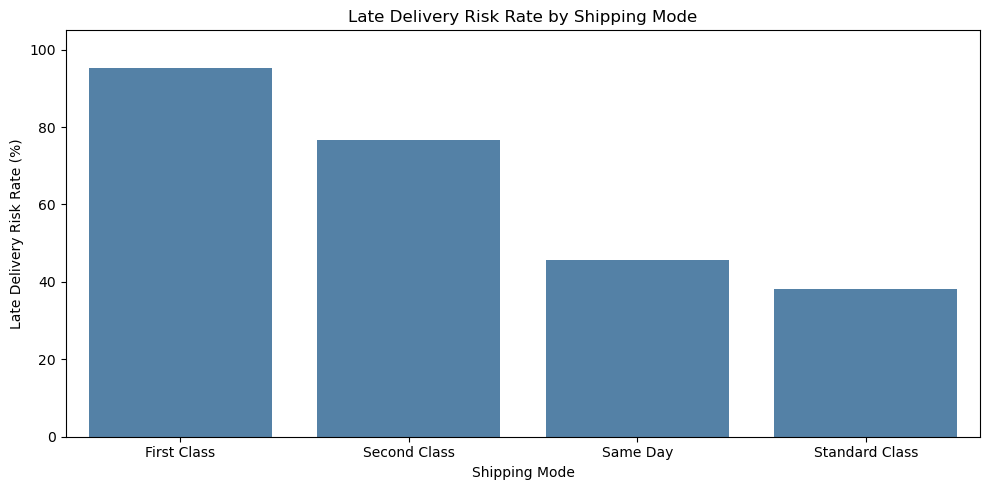

In [37]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=shipping_analysis,
    x="shipping_mode",
    y="late_delivery_risk_rate",
    color="steelblue"
)

plt.title("Late Delivery Risk Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Risk Rate (%)")
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

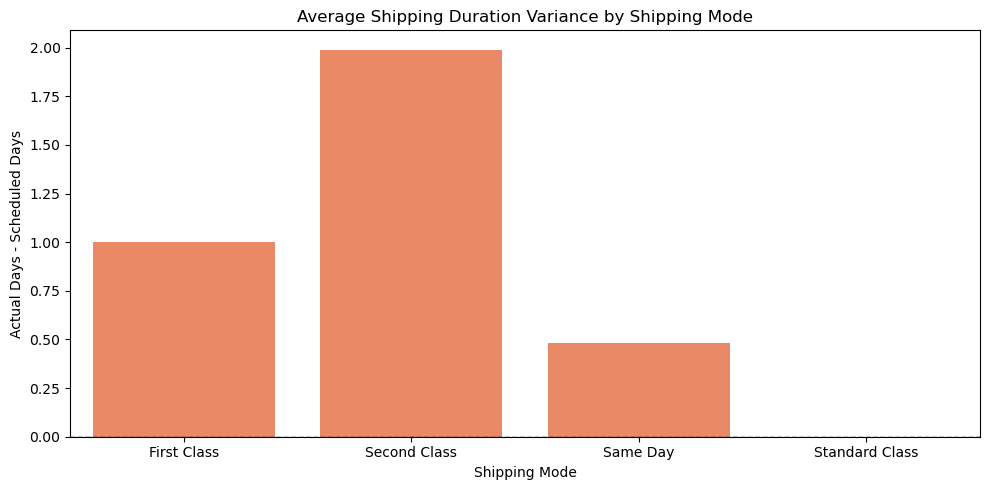

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=shipping_analysis,
    x="shipping_mode",
    y="avg_shipping_delay",
    color="coral"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Average Shipping Duration Variance by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Actual Days - Scheduled Days")

plt.tight_layout()
plt.show()

In [39]:
# Identify highest and lowest risk shipping modes

highest_risk = shipping_analysis.loc[
    shipping_analysis["late_delivery_risk_rate"].idxmax()
]

lowest_risk = shipping_analysis.loc[
    shipping_analysis["late_delivery_risk_rate"].idxmin()
]

# Calculate risk rate difference
risk_gap = (
    highest_risk["late_delivery_risk_rate"]
    - lowest_risk["late_delivery_risk_rate"]
)

print("SHIPPING PERFORMANCE INSIGHTS")
print("-" * 40)

print(
    f"Highest Risk Mode: {highest_risk['shipping_mode']} "
    f"({highest_risk['late_delivery_risk_rate']:.2f}%)"
)

print(
    f"Lowest Risk Mode: {lowest_risk['shipping_mode']} "
    f"({lowest_risk['late_delivery_risk_rate']:.2f}%)"
)

print(f"Risk Rate Difference: {risk_gap:.2f} percentage points")

SHIPPING PERFORMANCE INSIGHTS
----------------------------------------
Highest Risk Mode: First Class (95.32%)
Lowest Risk Mode: Standard Class (38.07%)
Risk Rate Difference: 57.25 percentage points


In [40]:
# Calculate monthly sales performance
monthly_sales = (
    df_clean.groupby("order_year_month")
    .agg(
        total_sales=("sales", "sum"),
        total_orders=("order_id", "nunique"),
        reported_profit=("order_profit_per_order", "sum")
    )
    .reset_index()
)

# Calculate reported monthly profit margin
monthly_sales["profit_margin_pct"] = (
    monthly_sales["reported_profit"]
    / monthly_sales["total_sales"] * 100
)

# Sort chronologically
monthly_sales = monthly_sales.sort_values(
    by="order_year_month"
)

display(monthly_sales.head(10))

,order_year_month,total_sales,total_orders,reported_profit,profit_margin_pct
0,2015-01,1.051590e+06,1787,111660.740132,10.618276
1,2015-02,9.270099e+05,1585,99140.660196,10.694671
2,2015-03,1.051254e+06,1781,113778.210191,10.823097
3,2015-04,1.014463e+06,1710,108083.679957,10.654272
4,2015-05,1.050478e+06,1776,112147.900143,10.675888
5,2015-06,1.024006e+06,1725,110147.160313,10.756494
6,2015-07,1.038081e+06,1763,115624.059879,11.138248
7,2015-08,1.029495e+06,1762,117979.770302,11.459969
8,2015-09,1.018339e+06,1706,113467.940118,11.142457
9,2015-10,1.049154e+06,1775,101757.870040,9.699038


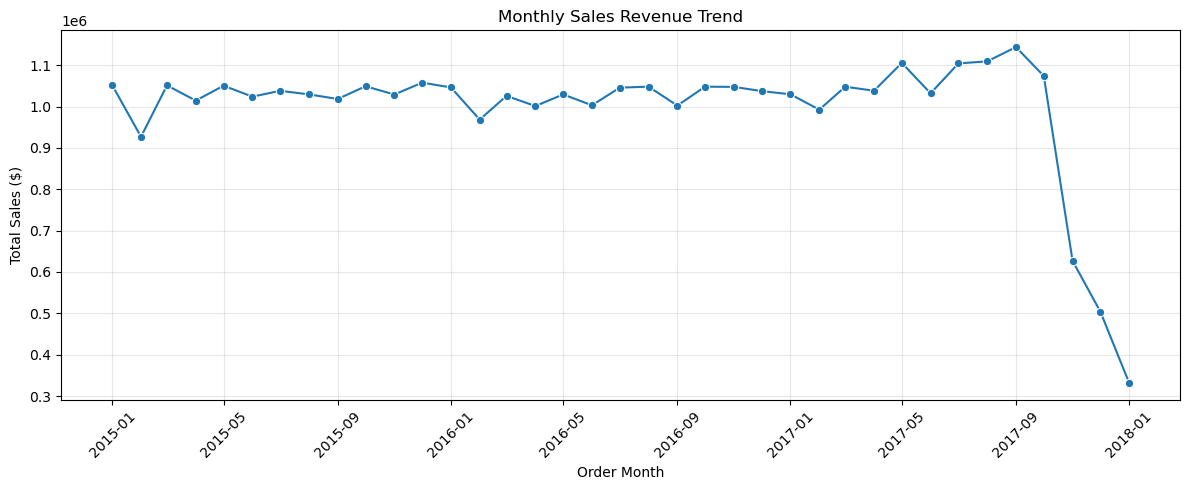

In [41]:
# Convert monthly periods to timestamps for plotting
monthly_sales["month_date"] = (
    monthly_sales["order_year_month"].dt.to_timestamp()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="month_date",
    y="total_sales",
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
highest_sales_month = monthly_sales.loc[
    monthly_sales["total_sales"].idxmax()
]

lowest_sales_month = monthly_sales.loc[
    monthly_sales["total_sales"].idxmin()
]

print("MONTHLY SALES INSIGHTS")
print("-" * 40)

print(
    f"Highest Sales Month: {highest_sales_month['order_year_month']}"
)

print(
    f"Sales: ${highest_sales_month['total_sales']:,.2f}"
)

print(
    f"Lowest Sales Month: {lowest_sales_month['order_year_month']}"
)

print(
    f"Sales: ${lowest_sales_month['total_sales']:,.2f}"
)

MONTHLY SALES INSIGHTS
----------------------------------------
Highest Sales Month: 2017-09
Sales: $1,143,775.11
Lowest Sales Month: 2018-01
Sales: $331,650.12


In [43]:
market_analysis = (
    df_clean.groupby("market")
    .agg(
        total_sales=("sales", "sum"),
        total_orders=("order_id", "nunique"),
        reported_profit=("order_profit_per_order", "sum")
    )
    .reset_index()
)

# Calculate market-level profit margin
market_analysis["profit_margin_pct"] = (
    market_analysis["reported_profit"]
    / market_analysis["total_sales"] * 100
)

# Sort markets by revenue
market_analysis = market_analysis.sort_values(
    by="total_sales",
    ascending=False
)

# Round results
market_analysis = market_analysis.round(2)

display(market_analysis)

,market,total_sales,total_orders,reported_profit,profit_margin_pct
1,Europe,10872396.80,18561,1169442.96,10.76
2,LATAM,10277612.84,17181,1123321.61,10.93
3,Pacific Asia,8273743.74,17577,857753.44,10.37
4,USCA,5066528.71,8579,564313.78,11.14
0,Africa,2294452.93,3854,252071.18,10.99


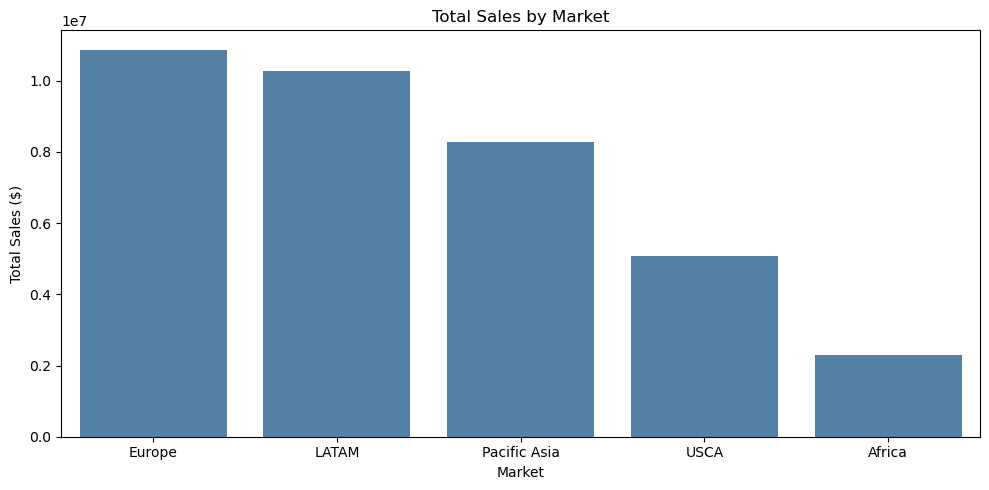

In [44]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=market_analysis,
    x="market",
    y="total_sales",
    color="steelblue"
)

plt.title("Total Sales by Market")
plt.xlabel("Market")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

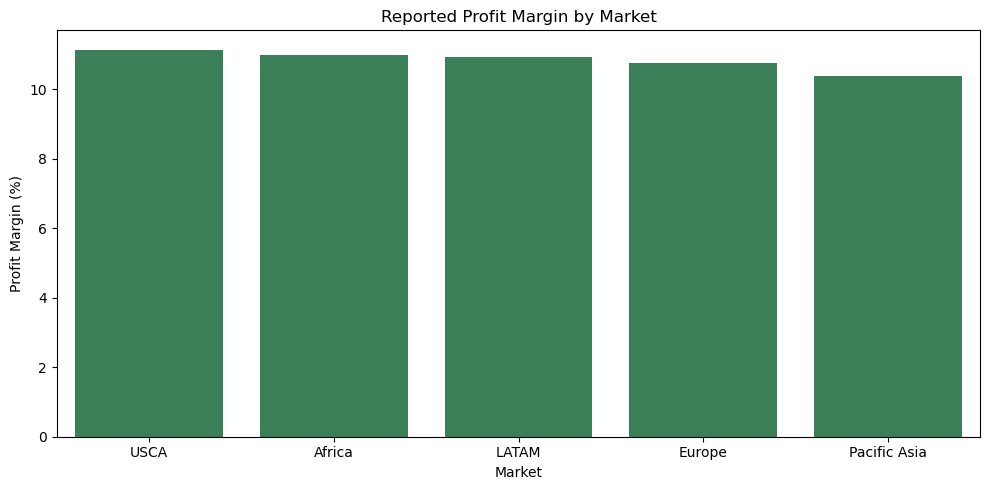

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=market_analysis.sort_values(
        "profit_margin_pct",
        ascending=False
    ),
    x="market",
    y="profit_margin_pct",
    color="seagreen"
)

plt.title("Reported Profit Margin by Market")
plt.xlabel("Market")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [46]:
highest_sales_market = market_analysis.loc[
    market_analysis["total_sales"].idxmax()
]

highest_margin_market = market_analysis.loc[
    market_analysis["profit_margin_pct"].idxmax()
]

print("MARKET PERFORMANCE INSIGHTS")
print("-" * 40)

print(
    f"Highest Revenue Market: "
    f"{highest_sales_market['market']}"
)

print(
    f"Revenue: ${highest_sales_market['total_sales']:,.2f}"
)

print(
    f"Highest Profit Margin Market: "
    f"{highest_margin_market['market']}"
)

print(
    f"Profit Margin: "
    f"{highest_margin_market['profit_margin_pct']:.2f}%"
)

MARKET PERFORMANCE INSIGHTS
----------------------------------------
Highest Revenue Market: Europe
Revenue: $10,872,396.80
Highest Profit Margin Market: USCA
Profit Margin: 11.14%


In [47]:
category_analysis = (
    df_clean.groupby("category_name")
    .agg(
        total_sales=("sales", "sum"),
        total_orders=("order_id", "nunique"),
        reported_profit=("order_profit_per_order", "sum"),
        total_quantity=("order_item_quantity", "sum")
    )
    .reset_index()
)

# Calculate reported profit margin
category_analysis["profit_margin_pct"] = (
    category_analysis["reported_profit"]
    / category_analysis["total_sales"] * 100
)

# Calculate sales contribution
category_analysis["sales_contribution_pct"] = (
    category_analysis["total_sales"]
    / df_clean["sales"].sum() * 100
)

category_analysis = category_analysis.round(2)

display(
    category_analysis.sort_values(
        "total_sales",
        ascending=False
    ).head(10)
)

,category_name,total_sales,total_orders,reported_profit,total_quantity,profit_margin_pct,sales_contribution_pct
18,Fishing,6929653.69,15164,756220.77,17325,10.91,18.84
12,Cleats,4431942.78,20386,494636.92,73734,11.16,12.05
9,Camping & Hiking,4118425.57,12299,427455.57,13729,10.38,11.20
10,Cardio Equipment,3694843.20,11355,383011.10,37587,10.37,10.04
47,Women's Apparel,3147800.00,17869,350421.03,62956,11.13,8.56
46,Water Sports,3113844.68,13758,325146.96,15540,10.44,8.47
34,Men's Footwear,2891757.66,18783,311902.82,22246,10.79,7.86
30,Indoor/Outdoor Games,2888993.91,16623,318451.43,57803,11.02,7.85
38,Shop By Sport,1309522.04,10136,129813.96,32726,9.91,3.56
13,Computers,663000.00,442,69656.81,442,10.51,1.80


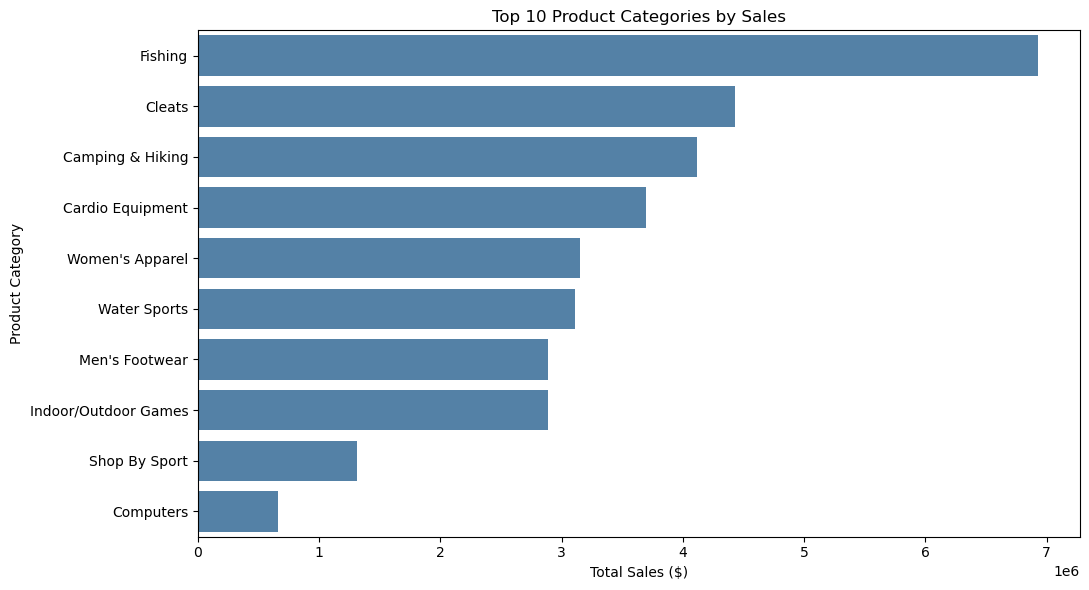

In [49]:
top_10_sales = category_analysis.nlargest(
    10, "total_sales"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_sales,
    x="total_sales",
    y="category_name",
    color="steelblue"
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [50]:
top_10_profit = category_analysis.nlargest(
    10, "reported_profit"
)

bottom_10_profit = category_analysis.nsmallest(
    10, "reported_profit"
)

print("TOP 10 CATEGORIES BY REPORTED PROFIT")
display(
    top_10_profit[
        ["category_name", "reported_profit", "profit_margin_pct"]
    ]
)

print("BOTTOM 10 CATEGORIES BY REPORTED PROFIT")
display(
    bottom_10_profit[
        ["category_name", "reported_profit", "profit_margin_pct"]
    ]
)

TOP 10 CATEGORIES BY REPORTED PROFIT


,category_name,reported_profit,profit_margin_pct
18,Fishing,756220.77,10.91
12,Cleats,494636.92,11.16
9,Camping & Hiking,427455.57,10.38
10,Cardio Equipment,383011.10,10.37
47,Women's Apparel,350421.03,11.13
46,Water Sports,325146.96,10.44
30,Indoor/Outdoor Games,318451.43,11.02
34,Men's Footwear,311902.82,10.79
38,Shop By Sport,129813.96,9.91
13,Computers,69656.81,10.51


BOTTOM 10 CATEGORIES BY REPORTED PROFIT


,category_name,reported_profit,profit_margin_pct
41,Strength Training,332.31,0.61
7,CDs,383.85,12.55
1,As Seen on TV!,714.43,3.47
5,Books,883.01,7.02
43,Toys,900.71,14.75
2,Baby,1525.03,12.47
23,Golf Bags & Carts,1810.07,17.46
4,Basketball,1845.67,6.81
33,Men's Clothing,2006.04,4.57
45,Video Games,2717.52,8.16


In [51]:
highest_sales_category = category_analysis.loc[
    category_analysis["total_sales"].idxmax()
]

highest_profit_category = category_analysis.loc[
    category_analysis["reported_profit"].idxmax()
]

lowest_profit_category = category_analysis.loc[
    category_analysis["reported_profit"].idxmin()
]

print("PRODUCT CATEGORY INSIGHTS")
print("-" * 45)

print(
    f"Highest Sales Category: "
    f"{highest_sales_category['category_name']}"
)

print(
    f"Sales: ${highest_sales_category['total_sales']:,.2f}"
)

print(
    f"Highest Profit Category: "
    f"{highest_profit_category['category_name']}"
)

print(
    f"Profit: ${highest_profit_category['reported_profit']:,.2f}"
)

print(
    f"Lowest Profit Category: "
    f"{lowest_profit_category['category_name']}"
)

print(
    f"Profit: ${lowest_profit_category['reported_profit']:,.2f}"
)

PRODUCT CATEGORY INSIGHTS
---------------------------------------------
Highest Sales Category: Fishing
Sales: $6,929,653.69
Highest Profit Category: Fishing
Profit: $756,220.77
Lowest Profit Category: Strength Training
Profit: $332.31


In [52]:
customer_segment_analysis = (
    df_clean.groupby("customer_segment")
    .agg(
        total_sales=("sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        reported_profit=("order_profit_per_order", "sum")
    )
    .reset_index()
)

# Calculate reported profit margin
customer_segment_analysis["profit_margin_pct"] = (
    customer_segment_analysis["reported_profit"]
    / customer_segment_analysis["total_sales"] * 100
)

# Calculate average order value
customer_segment_analysis["avg_order_value"] = (
    customer_segment_analysis["total_sales"]
    / customer_segment_analysis["total_orders"]
)

# Calculate revenue contribution
customer_segment_analysis["sales_contribution_pct"] = (
    customer_segment_analysis["total_sales"]
    / df_clean["sales"].sum() * 100
)

# Round results
customer_segment_analysis = (
    customer_segment_analysis.round(2)
    .sort_values("total_sales", ascending=False)
)

display(customer_segment_analysis)

,customer_segment,total_sales,total_orders,total_customers,reported_profit,profit_margin_pct,avg_order_value,sales_contribution_pct
0,Consumer,19095790.16,34119,10695,2073487.67,10.86,559.68,51.91
1,Corporate,11168406.84,19856,6239,1202574.96,10.77,562.47,30.36
2,Home Office,6520538.02,11777,3718,690840.34,10.59,553.67,17.73


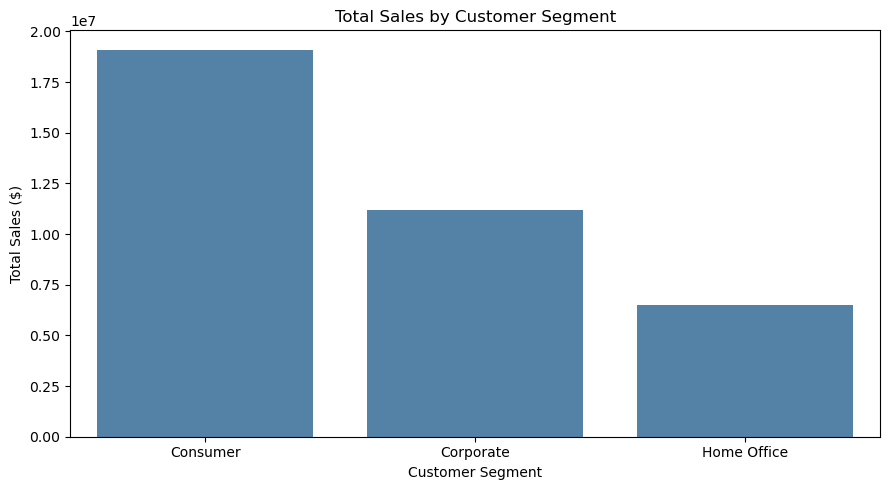

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_segment_analysis,
    x="customer_segment",
    y="total_sales",
    color="steelblue"
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

In [54]:
top_segment = customer_segment_analysis.loc[
    customer_segment_analysis["total_sales"].idxmax()
]

print("CUSTOMER SEGMENT INSIGHTS")
print("-" * 40)

print(f"Highest Revenue Segment: {top_segment['customer_segment']}")
print(f"Total Sales: ${top_segment['total_sales']:,.2f}")
print(f"Total Customers: {top_segment['total_customers']:,}")
print(f"Average Order Value: ${top_segment['avg_order_value']:,.2f}")
print(f"Sales Contribution: {top_segment['sales_contribution_pct']:.2f}%")

CUSTOMER SEGMENT INSIGHTS
----------------------------------------
Highest Revenue Segment: Consumer
Total Sales: $19,095,790.16
Total Customers: 10,695
Average Order Value: $559.68
Sales Contribution: 51.91%


In [55]:
regional_analysis = (
    df_clean.groupby("order_region")
    .agg(
        total_sales=("sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        reported_profit=("order_profit_per_order", "sum"),
        late_delivery_risk_rate=("late_delivery_risk", "mean")
    )
    .reset_index()
)

# Calculate profit margin
regional_analysis["profit_margin_pct"] = (
    regional_analysis["reported_profit"]
    / regional_analysis["total_sales"] * 100
)

# Convert risk rate to percentage
regional_analysis["late_delivery_risk_rate"] *= 100

# Calculate sales contribution
regional_analysis["sales_contribution_pct"] = (
    regional_analysis["total_sales"]
    / df_clean["sales"].sum() * 100
)

# Round and sort
regional_analysis = (
    regional_analysis.round(2)
    .sort_values("total_sales", ascending=False)
)

display(regional_analysis.head(10))

,order_region,total_sales,total_orders,total_customers,reported_profit,late_delivery_risk_rate,profit_margin_pct,sales_contribution_pct
22,Western Europe,5894380.77,10010,7695,625446.08,55.85,10.61,16.02
3,Central America,5665712.10,9396,6564,616341.57,54.75,10.88,15.40
12,South America,2960881.41,4979,4131,335154.40,54.31,11.32,8.05
10,Northern Europe,2155830.65,3716,3340,233450.60,54.04,10.83,5.86
17,Southern Europe,2047918.82,3543,3192,230829.23,54.38,11.27,5.57
11,Oceania,2016654.20,4362,4042,201478.02,54.02,9.99,5.48
15,Southeast Asia,1932495.57,4356,4101,211342.82,55.53,10.94,5.25
1,Caribbean,1651019.33,2806,2506,171825.64,53.08,10.41,4.49
21,West of USA,1571415.96,2667,2400,164940.66,53.96,10.50,4.27
13,South Asia,1553680.92,3335,3153,165703.90,56.27,10.67,4.22


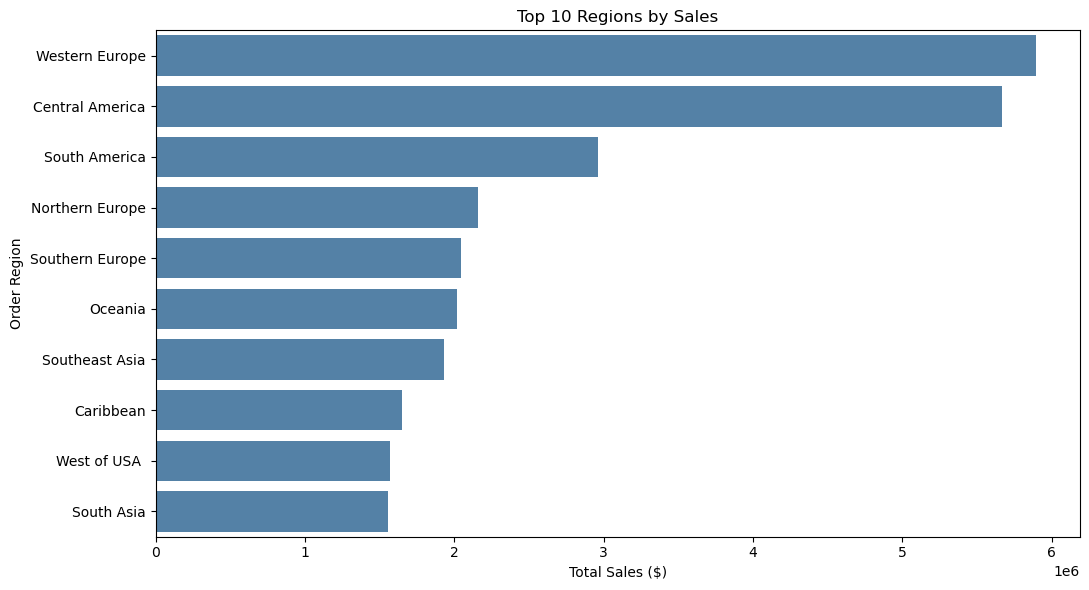

In [56]:
top_10_regions = regional_analysis.nlargest(
    10, "total_sales"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_regions,
    x="total_sales",
    y="order_region",
    color="steelblue"
)

plt.title("Top 10 Regions by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Order Region")

plt.tight_layout()
plt.show()

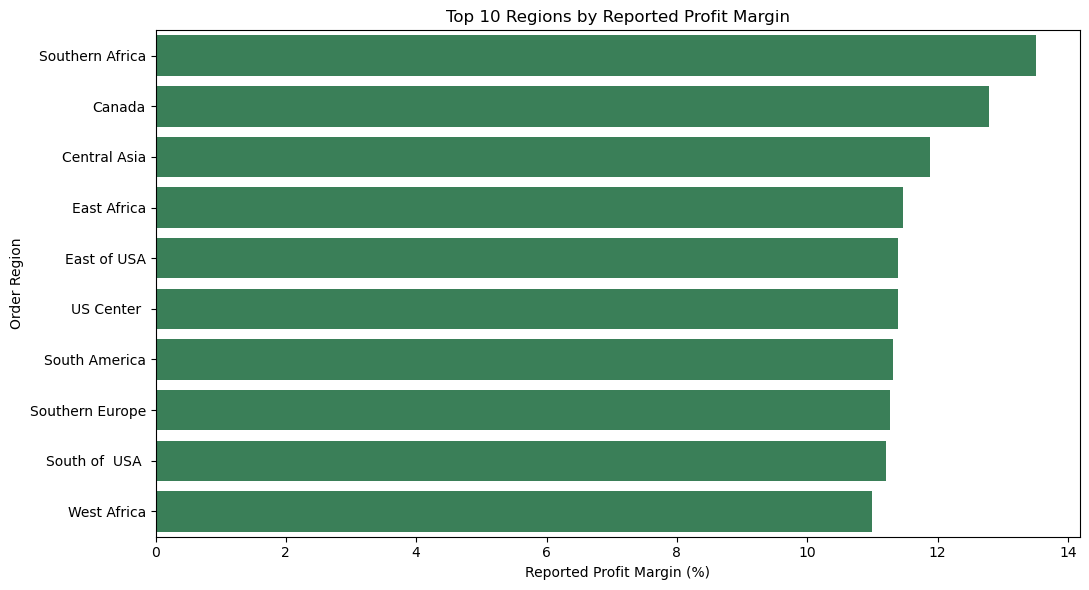

In [57]:
top_10_margin_regions = regional_analysis.nlargest(
    10, "profit_margin_pct"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_margin_regions,
    x="profit_margin_pct",
    y="order_region",
    color="seagreen"
)

plt.title("Top 10 Regions by Reported Profit Margin")
plt.xlabel("Reported Profit Margin (%)")
plt.ylabel("Order Region")

plt.tight_layout()
plt.show()

In [58]:
highest_sales_region = regional_analysis.loc[
    regional_analysis["total_sales"].idxmax()
]

highest_margin_region = regional_analysis.loc[
    regional_analysis["profit_margin_pct"].idxmax()
]

highest_risk_region = regional_analysis.loc[
    regional_analysis["late_delivery_risk_rate"].idxmax()
]

print("REGIONAL PERFORMANCE INSIGHTS")
print("-" * 45)

print(
    f"Highest Sales Region: "
    f"{highest_sales_region['order_region']}"
)

print(
    f"Sales: ${highest_sales_region['total_sales']:,.2f}"
)

print(
    f"Highest Profit Margin Region: "
    f"{highest_margin_region['order_region']}"
)

print(
    f"Profit Margin: "
    f"{highest_margin_region['profit_margin_pct']:.2f}%"
)

print(
    f"Highest Delivery Risk Region: "
    f"{highest_risk_region['order_region']}"
)

print(
    f"Late Delivery Risk Rate: "
    f"{highest_risk_region['late_delivery_risk_rate']:.2f}%"
)

REGIONAL PERFORMANCE INSIGHTS
---------------------------------------------
Highest Sales Region: Western Europe
Sales: $5,894,380.77
Highest Profit Margin Region: Southern Africa
Profit Margin: 13.51%
Highest Delivery Risk Region: Central Africa
Late Delivery Risk Rate: 57.96%


In [59]:
# Overall business KPIs

total_records = len(df_clean)

total_orders = df_clean["order_id"].nunique()

total_customers = df_clean["customer_id"].nunique()

total_sales = df_clean["sales"].sum()

reported_profit = df_clean["order_profit_per_order"].sum()

reported_profit_margin = (
    reported_profit / total_sales * 100
)

late_delivery_risk_rate = (
    df_clean["late_delivery_risk"].mean() * 100
)

late_shipment_rate = (
    df_clean["is_late_shipment"].mean() * 100
)

avg_shipping_delay = (
    df_clean["shipping_delay_days"].mean()
)

loss_making_records = (
    df_clean["is_loss_making"].sum()
)

loss_making_pct = (
    df_clean["is_loss_making"].mean() * 100
)

# Consolidated KPI table

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Records",
        "Unique Orders",
        "Unique Customers",
        "Total Sales ($)",
        "Reported Profit ($)",
        "Reported Profit Margin (%)",
        "Late Delivery Risk Rate (%)",
        "Late Shipment Rate (%)",
        "Average Shipping Variance (Days)",
        "Loss-Making Records",
        "Loss-Making Records (%)"
    ],
    "Value": [
        total_records,
        total_orders,
        total_customers,
        round(total_sales, 2),
        round(reported_profit, 2),
        round(reported_profit_margin, 2),
        round(late_delivery_risk_rate, 2),
        round(late_shipment_rate, 2),
        round(avg_shipping_delay, 2),
        loss_making_records,
        round(loss_making_pct, 2)
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Records,180519.00
1,Unique Orders,65752.00
2,Unique Customers,20652.00
3,Total Sales ($),36784735.01
4,Reported Profit ($),3966902.97
5,Reported Profit Margin (%),10.78
6,Late Delivery Risk Rate (%),54.83
7,Late Shipment Rate (%),57.28
8,Average Shipping Variance (Days),0.57
9,Loss-Making Records,33784.00


In [60]:
# Compare Python KPIs against previously recorded Power BI KPIs

expected_kpis = {
    "Total Records": 180519,
    "Unique Orders": 65752,
    "Unique Customers": 20652,
    "Total Sales ($)": 36784735.01,
    "Reported Profit ($)": 3966902.97,
    "Reported Profit Margin (%)": 10.78,
    "Late Delivery Risk Rate (%)": 54.83,
    "Late Shipment Rate (%)": 57.28,
    "Average Shipping Variance (Days)": 0.57,
    "Loss-Making Records": 33784,
    "Loss-Making Records (%)": 18.71
}

validation = kpi_summary.copy()

validation["Expected"] = validation["KPI"].map(expected_kpis)

validation["Difference"] = (
    validation["Value"] - validation["Expected"]
).round(2)

validation["Status"] = np.where(
    np.isclose(
        validation["Value"],
        validation["Expected"],
        atol=0.01,
        rtol=0
    ),
    "PASS",
    "CHECK"
)

display(validation)

,KPI,Value,Expected,Difference,Status
0,Total Records,180519.00,180519.00,0.0,PASS
1,Unique Orders,65752.00,65752.00,0.0,PASS
2,Unique Customers,20652.00,20652.00,0.0,PASS
3,Total Sales ($),36784735.01,36784735.01,0.0,PASS
4,Reported Profit ($),3966902.97,3966902.97,0.0,PASS
5,Reported Profit Margin (%),10.78,10.78,0.0,PASS
6,Late Delivery Risk Rate (%),54.83,54.83,0.0,PASS
7,Late Shipment Rate (%),57.28,57.28,0.0,PASS
8,Average Shipping Variance (Days),0.57,0.57,0.0,PASS
9,Loss-Making Records,33784.00,33784.00,0.0,PASS


In [61]:
print("=" * 60)
print("SUPPLY CHAIN & LOGISTICS - BUSINESS INSIGHTS")
print("=" * 60)

# 1. Shipping performance
highest_risk_mode = shipping_analysis.loc[
    shipping_analysis["late_delivery_risk_rate"].idxmax()
]

print("\n1. SHIPPING PERFORMANCE")
print(
    f"Highest delivery risk: "
    f"{highest_risk_mode['shipping_mode']} "
    f"({highest_risk_mode['late_delivery_risk_rate']:.2f}%)"
)

# 2. Market performance
top_market = market_analysis.loc[
    market_analysis["total_sales"].idxmax()
]

print("\n2. MARKET PERFORMANCE")
print(
    f"Highest revenue market: {top_market['market']} "
    f"(${top_market['total_sales']:,.2f})"
)

# 3. Category performance
top_category = category_analysis.loc[
    category_analysis["total_sales"].idxmax()
]

print("\n3. PRODUCT PERFORMANCE")
print(
    f"Highest revenue category: {top_category['category_name']} "
    f"(${top_category['total_sales']:,.2f})"
)

# 4. Customer performance
top_segment = customer_segment_analysis.loc[
    customer_segment_analysis["total_sales"].idxmax()
]

print("\n4. CUSTOMER PERFORMANCE")
print(
    f"Highest revenue segment: {top_segment['customer_segment']} "
    f"(${top_segment['total_sales']:,.2f})"
)

# 5. Regional performance
top_region = regional_analysis.loc[
    regional_analysis["total_sales"].idxmax()
]

print("\n5. REGIONAL PERFORMANCE")
print(
    f"Highest revenue region: {top_region['order_region']} "
    f"(${top_region['total_sales']:,.2f})"
)

SUPPLY CHAIN & LOGISTICS - BUSINESS INSIGHTS

1. SHIPPING PERFORMANCE
Highest delivery risk: First Class (95.32%)

2. MARKET PERFORMANCE
Highest revenue market: Europe ($10,872,396.80)

3. PRODUCT PERFORMANCE
Highest revenue category: Fishing ($6,929,653.69)

4. CUSTOMER PERFORMANCE
Highest revenue segment: Consumer ($19,095,790.16)

5. REGIONAL PERFORMANCE
Highest revenue region: Western Europe ($5,894,380.77)


### Business Conclusion

The Supply Chain & Logistics Performance Analytics project analyzed 180,519 order-item records to evaluate shipping efficiency, sales performance, reported profitability, customer segments, and regional operations.

The analysis identified significant differences in delivery-risk flags across shipping modes, with First Class recording the highest risk rate at 95.32% and Standard Class the lowest at 38.07%. Additionally, 57.28% of records showed actual shipping durations exceeding scheduled durations, highlighting opportunities to investigate fulfillment and scheduling performance.

The project also examined revenue concentration, product-category performance, customer segments, and regional differences to identify potential operational and commercial improvement opportunities.

**Recommendations:** Investigate high-risk shipping modes, review fulfillment scheduling, examine loss-making transactions, and prioritize deeper analysis of high-revenue markets and categories.

**Data limitations:** Delivery-risk indicators should not be interpreted as confirmed late arrivals. Reported profit figures require further validation before they are used for financial decision-making.

In [62]:
##  Export Cleaned Dataset
# Create a copy for export
df_export = df_clean.copy()

# Convert monthly Period values to strings
df_export["order_year_month"] = (
    df_export["order_year_month"].astype(str)
)

# Check dataset dimensions
print("Rows:", df_export.shape[0])
print("Columns:", df_export.shape[1])

# Check duplicate order-item IDs
print(
    "Duplicate Order Item IDs:",
    df_export["order_item_id"].duplicated().sum()
)

Rows: 180519
Columns: 55
Duplicate Order Item IDs: 0


In [63]:
# Define export location
output_path = Path("../data/supply_chain_cleaned.csv")

# Export cleaned data
df_export.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

print("Cleaned dataset exported successfully!")
print("Saved to:", output_path.resolve())

Cleaned dataset exported successfully!
Saved to: /Applications/All Documents/projects/Supply-Chain-Logistics-Performance-Analytics/data/supply_chain_cleaned.csv


In [64]:
# Reload exported dataset
df_verify = pd.read_csv(
    "../data/supply_chain_cleaned.csv",
    low_memory=False
)

print("Original cleaned shape:", df_clean.shape)
print("Exported CSV shape:", df_verify.shape)

print(
    "Row count matches:",
    len(df_clean) == len(df_verify)
)

print(
    "Column names match:",
    list(df_clean.columns) == list(df_verify.columns)
)

print(
    "Total sales matches:",
    np.isclose(
        df_clean["sales"].sum(),
        df_verify["sales"].sum()
    )
)

display(df_verify.head())

Original cleaned shape: (180519, 55)
Exported CSV shape: (180519, 55)
Row count matches: True
Column names match: True
Total sales matches: True


,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_id,customer_segment,customer_state,department_id,department_name,market,order_city,order_country,order_customer_id,order_date_dateorders,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode,shipping_delay_days,is_late_shipment,shipping_performance,order_year,order_month,order_quarter,order_year_month,profit_margin_pct,profit_status,is_loss_making
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,2,Fitness,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,-1,0,Early,2018,1,1,2018-01,27.841342,Profit,0
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,2,Fitness,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,1,1,Delayed,2018,1,1,2018-01,-75.999999,Loss,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,2,Fitness,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,0,0,On Time,2018,1,1,2018-01,-75.600305,Loss,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,2,Fitness,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,-1,0,Early,2018,1,1,2018-01,6.974829,Profit,0
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,2,Fitness,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,-2,0,Early,2018,1,1,2018-01,40.948896,Profit,0


In [65]:
# Reload exported dataset
df_verify = pd.read_csv(
    "../data/supply_chain_cleaned.csv",
    low_memory=False
)

print("Original cleaned shape:", df_clean.shape)
print("Exported CSV shape:", df_verify.shape)

print(
    "Row count matches:",
    len(df_clean) == len(df_verify)
)

print(
    "Column names match:",
    list(df_clean.columns) == list(df_verify.columns)
)

print(
    "Total sales matches:",
    np.isclose(
        df_clean["sales"].sum(),
        df_verify["sales"].sum()
    )
)

display(df_verify.head())

Original cleaned shape: (180519, 55)
Exported CSV shape: (180519, 55)
Row count matches: True
Column names match: True
Total sales matches: True


,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_id,customer_segment,customer_state,department_id,department_name,market,order_city,order_country,order_customer_id,order_date_dateorders,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode,shipping_delay_days,is_late_shipment,shipping_performance,order_year,order_month,order_quarter,order_year_month,profit_margin_pct,profit_status,is_loss_making
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,2,Fitness,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,-1,0,Early,2018,1,1,2018-01,27.841342,Profit,0
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,2,Fitness,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,1,1,Delayed,2018,1,1,2018-01,-75.999999,Loss,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,2,Fitness,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,0,0,On Time,2018,1,1,2018-01,-75.600305,Loss,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,2,Fitness,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,-1,0,Early,2018,1,1,2018-01,6.974829,Profit,0
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,2,Fitness,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,-2,0,Early,2018,1,1,2018-01,40.948896,Profit,0


In [66]:
# Check all columns and their data types
for col, dtype in df_export.dtypes.items():
    print(f"{col}: {dtype}")

type: object
days_for_shipping_real: int64
days_for_shipment_scheduled: int64
benefit_per_order: float64
sales_per_customer: float64
delivery_status: object
late_delivery_risk: int64
category_id: int64
category_name: object
customer_city: object
customer_country: object
customer_id: int64
customer_segment: object
customer_state: object
department_id: int64
department_name: object
market: object
order_city: object
order_country: object
order_customer_id: int64
order_date_dateorders: datetime64[ns]
order_id: int64
order_item_cardprod_id: int64
order_item_discount: float64
order_item_discount_rate: float64
order_item_id: int64
order_item_product_price: float64
order_item_profit_ratio: float64
order_item_quantity: int64
sales: float64
order_item_total: float64
order_profit_per_order: float64
order_region: object
order_state: object
order_status: object
order_zipcode: float64
product_card_id: int64
product_category_id: int64
product_description: float64
product_image: object
product_name: o

In [67]:
print("Total columns:", len(df_export.columns))
print("Total rows:", len(df_export))

Total columns: 55
Total rows: 180519


In [69]:
import pandas as pd
from pandas.api.types import (
    is_integer_dtype,
    is_float_dtype,
    is_datetime64_any_dtype,
    is_bool_dtype
)

def postgres_type(dtype):
    if is_integer_dtype(dtype):
        return "BIGINT"
    elif is_float_dtype(dtype):
        return "DOUBLE PRECISION"
    elif is_datetime64_any_dtype(dtype):
        return "TIMESTAMP"
    elif is_bool_dtype(dtype):
        return "BOOLEAN"
    else:
        return "TEXT"

columns = []

for col, dtype in df_export.dtypes.items():
    sql_type = postgres_type(dtype)
    safe_col = col.replace('"', '""')
    columns.append(f'    "{safe_col}" {sql_type}')

create_table_sql = (
    "CREATE TABLE IF NOT EXISTS supply_chain_orders (\n"
    + ",\n".join(columns)
    + "\n);"
)

print(create_table_sql)

CREATE TABLE IF NOT EXISTS supply_chain_orders (
    "type" TEXT,
    "days_for_shipping_real" BIGINT,
    "days_for_shipment_scheduled" BIGINT,
    "benefit_per_order" DOUBLE PRECISION,
    "sales_per_customer" DOUBLE PRECISION,
    "delivery_status" TEXT,
    "late_delivery_risk" BIGINT,
    "category_id" BIGINT,
    "category_name" TEXT,
    "customer_city" TEXT,
    "customer_country" TEXT,
    "customer_id" BIGINT,
    "customer_segment" TEXT,
    "customer_state" TEXT,
    "department_id" BIGINT,
    "department_name" TEXT,
    "market" TEXT,
    "order_city" TEXT,
    "order_country" TEXT,
    "order_customer_id" BIGINT,
    "order_date_dateorders" TIMESTAMP,
    "order_id" BIGINT,
    "order_item_cardprod_id" BIGINT,
    "order_item_discount" DOUBLE PRECISION,
    "order_item_discount_rate" DOUBLE PRECISION,
    "order_item_id" BIGINT,
    "order_item_product_price" DOUBLE PRECISION,
    "order_item_profit_ratio" DOUBLE PRECISION,
    "order_item_quantity" BIGINT,
    "sales" D